----2026/11/11-----

本 notebook 基于 Roboflow 的示例笔记本改编，使用 YOLOv8s-seg 预训练模型进行自定义数据集的实例分割训练。主要包括数据集加载与配置、模型训练、验证集预测、结果可视化，以及训练结果的打包下载

[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLOv8 Object Detection on a Custom Dataset

---

[![Roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset)
[![YouTube](https://badges.aleen42.com/src/youtube.svg)](https://youtu.be/wuZtUMEiKWY)
[![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

Ultralytics YOLOv8 is a popular version of the YOLO (You Only Look Once) object detection and image segmentation model developed by Ultralytics. The YOLOv8 model is designed to be fast, accurate, and easy to use, making it an excellent choice for a wide range of object detection and image segmentation tasks. It can be trained on large datasets and is capable of running on a variety of hardware platforms, from CPUs to GPUs.

## Disclaimer

If you notice that our notebook behaves incorrectly - especially if you experience errors that prevent you from going through the tutorial - don't hesitate! Let us know and open an [issue](https://github.com/roboflow/notebooks/issues) on the Roboflow Notebooks repository.

## Accompanying Blog Post

We recommend that you follow along in this notebook while reading the accompanying [Blog Post](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset/).

## Pro Tip: Use GPU Acceleration

If you are running this notebook in Google Colab, navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`. This will ensure your notebook uses a GPU, which will significantly speed up model training times.

## Steps in this Tutorial

In this tutorial, we are going to cover:

- Before you start
- Install YOLOv8
- CLI Basics
- Inference with Pre-trained COCO Model
- Roboflow Universe
- Preparing a custom dataset
- Custom Training
- Validate Custom Model
- Inference with Custom Model

**Let's begin!**

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [ ]:
print('new run start')

new run start


In [ ]:
!nvidia-smi

Fri Oct  9 01:22:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [ ]:
!pip install -q ultralytics
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.1 MB/s eta 0:00:00
True
Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
from IPython.display import display, Image
model = YOLO("yolov8s-seg.pt")

### 首次标注：加载人工标注数据集

从 Google Drive 下载并解压人工标注后的 YOLO 数据集。数据集目录结构如下：

```text
YOLO_dataset/
├── images/
│   ├── train/
│   └── val/
└── labels/
    ├── train/
    └── val/
```

其中，`images` 存放训练和验证图像，`labels` 存放对应的 YOLO 格式标注文件。

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/YOLO_dataset.zip" /content/
!unzip -q /content/YOLO_dataset.zip -d /content/
!ls -lh /content/YOLO_dataset.zip
!file /content/YOLO_dataset.zip

Mounted at /content/drive
-rw------- 1 root root 478M Oct  9 01:23 /content/YOLO_dataset_aug.zip
/content/YOLO_dataset_aug.zip: Zip archive data, at least v2.0 to extract, compression method=store
replace /content/YOLO_dataset_aug/.DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/__MACOSX/YOLO_dataset_aug/._.DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/YOLO_dataset_aug/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
A


In [ ]:
%%writefile /content/YOLO_dataset_aug/data.yaml
path: /content/YOLO_dataset_aug

train: images/train
val: images/val

names:
  0: patient
  1: metal
  2: fabric

Overwriting /content/YOLO_dataset_aug/data.yaml


### 训练集数据增强

在模型训练前，对 `images/train` 中的原始灰度图像分别进行高斯噪声添加、CLAHE（对比度受限自适应直方图均衡化）和对比度调整，每张原始图像生成三个增强版本。

增强图像保存至原 `images/train` 文件夹，文件名分别添加 `__aug_noise`、`__aug_clahe` 和 `__aug_contrast` 后缀，原始图像保留。

上述操作不改变图像尺寸和目标位置，因此无需修改分割标注，只需将对应的 YOLO `.txt` 标注文件复制至 `labels/train`，并使用与增强图像一致的文件名主干。

仅对训练集进行增强，验证集保持不变。重复运行时，跳过本段代码已生成的增强图像和标注，避免重复增强。

In [ ]:
from pathlib import Path
import shutil

import cv2
import numpy as np
from skimage.util import random_noise


def add_noise(img):
    sigma = np.random.uniform(2, 8)
    noisy = random_noise(
        img,
        mode="gaussian",
        var=(sigma / 255) ** 2
    )
    return (noisy * 255).astype(np.uint8)


def add_clahe(img):
    clahe = cv2.createCLAHE(
        clipLimit=np.random.uniform(1.5, 3.0),
        tileGridSize=(8, 8)
    )
    return clahe.apply(img)


def adjust_contrast(img):
    alpha = np.random.uniform(0.85, 1.4)
    x = img.astype(np.float32) / 255
    mean = x.mean()
    x = (x - mean) * alpha + mean
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)


# 修改为实际数据集路径
dataset_dir = Path("/content/YOLO_dataset_aug")
image_dir = dataset_dir / "images" / "train"
label_dir = dataset_dir / "labels" / "train"

if not image_dir.is_dir() or not label_dir.is_dir():
    raise FileNotFoundError("请检查 images/train 和 labels/train 路径。")

augmentations = {
    "noise": add_noise,
    "clahe": add_clahe,
    "contrast": adjust_contrast,
}

# 先获取原始图像列表，排除本段代码生成的增强版本，
# 避免重复运行时对增强图像再次增强。
image_extensions = {".png", ".jpg", ".jpeg"}
augmentation_suffixes = tuple(
    f"__aug_{name}" for name in augmentations
)

original_images = sorted(
    path for path in image_dir.iterdir()
    if path.suffix.lower() in image_extensions
    and not path.stem.endswith(augmentation_suffixes)
)

created = 0

for image_path in original_images:
    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.is_file():
        print(f"跳过：缺少标注文件 {label_path.name}")
        continue

    # 按当前增强函数的要求，以 8 位灰度图读取
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"跳过：无法读取 {image_path.name}")
        continue

    for name, augment in augmentations.items():
        new_stem = f"{image_path.stem}__aug_{name}"
        new_image_path = image_dir / f"{new_stem}.png"
        new_label_path = label_dir / f"{new_stem}.txt"

        # 已存在的完整图像—标注对不重复生成
        if new_image_path.exists() and new_label_path.exists():
            continue

        augmented = augment(img)

        if not cv2.imwrite(str(new_image_path), augmented):
            raise IOError(f"保存图像失败：{new_image_path}")

        # 图像与标注使用相同文件名主干
        shutil.copy2(label_path, new_label_path)
        created += 1

print(f"完成：新增 {created} 张增强图像及对应标注。")

In [ ]:
!yolo task=segment mode=train model=yolov8s-seg.pt data=/content/YOLO_dataset_aug/data.yaml epochs=50 imgsz=640 batch=8 device=0

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/YOLO_dataset_aug/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=Fa

/content


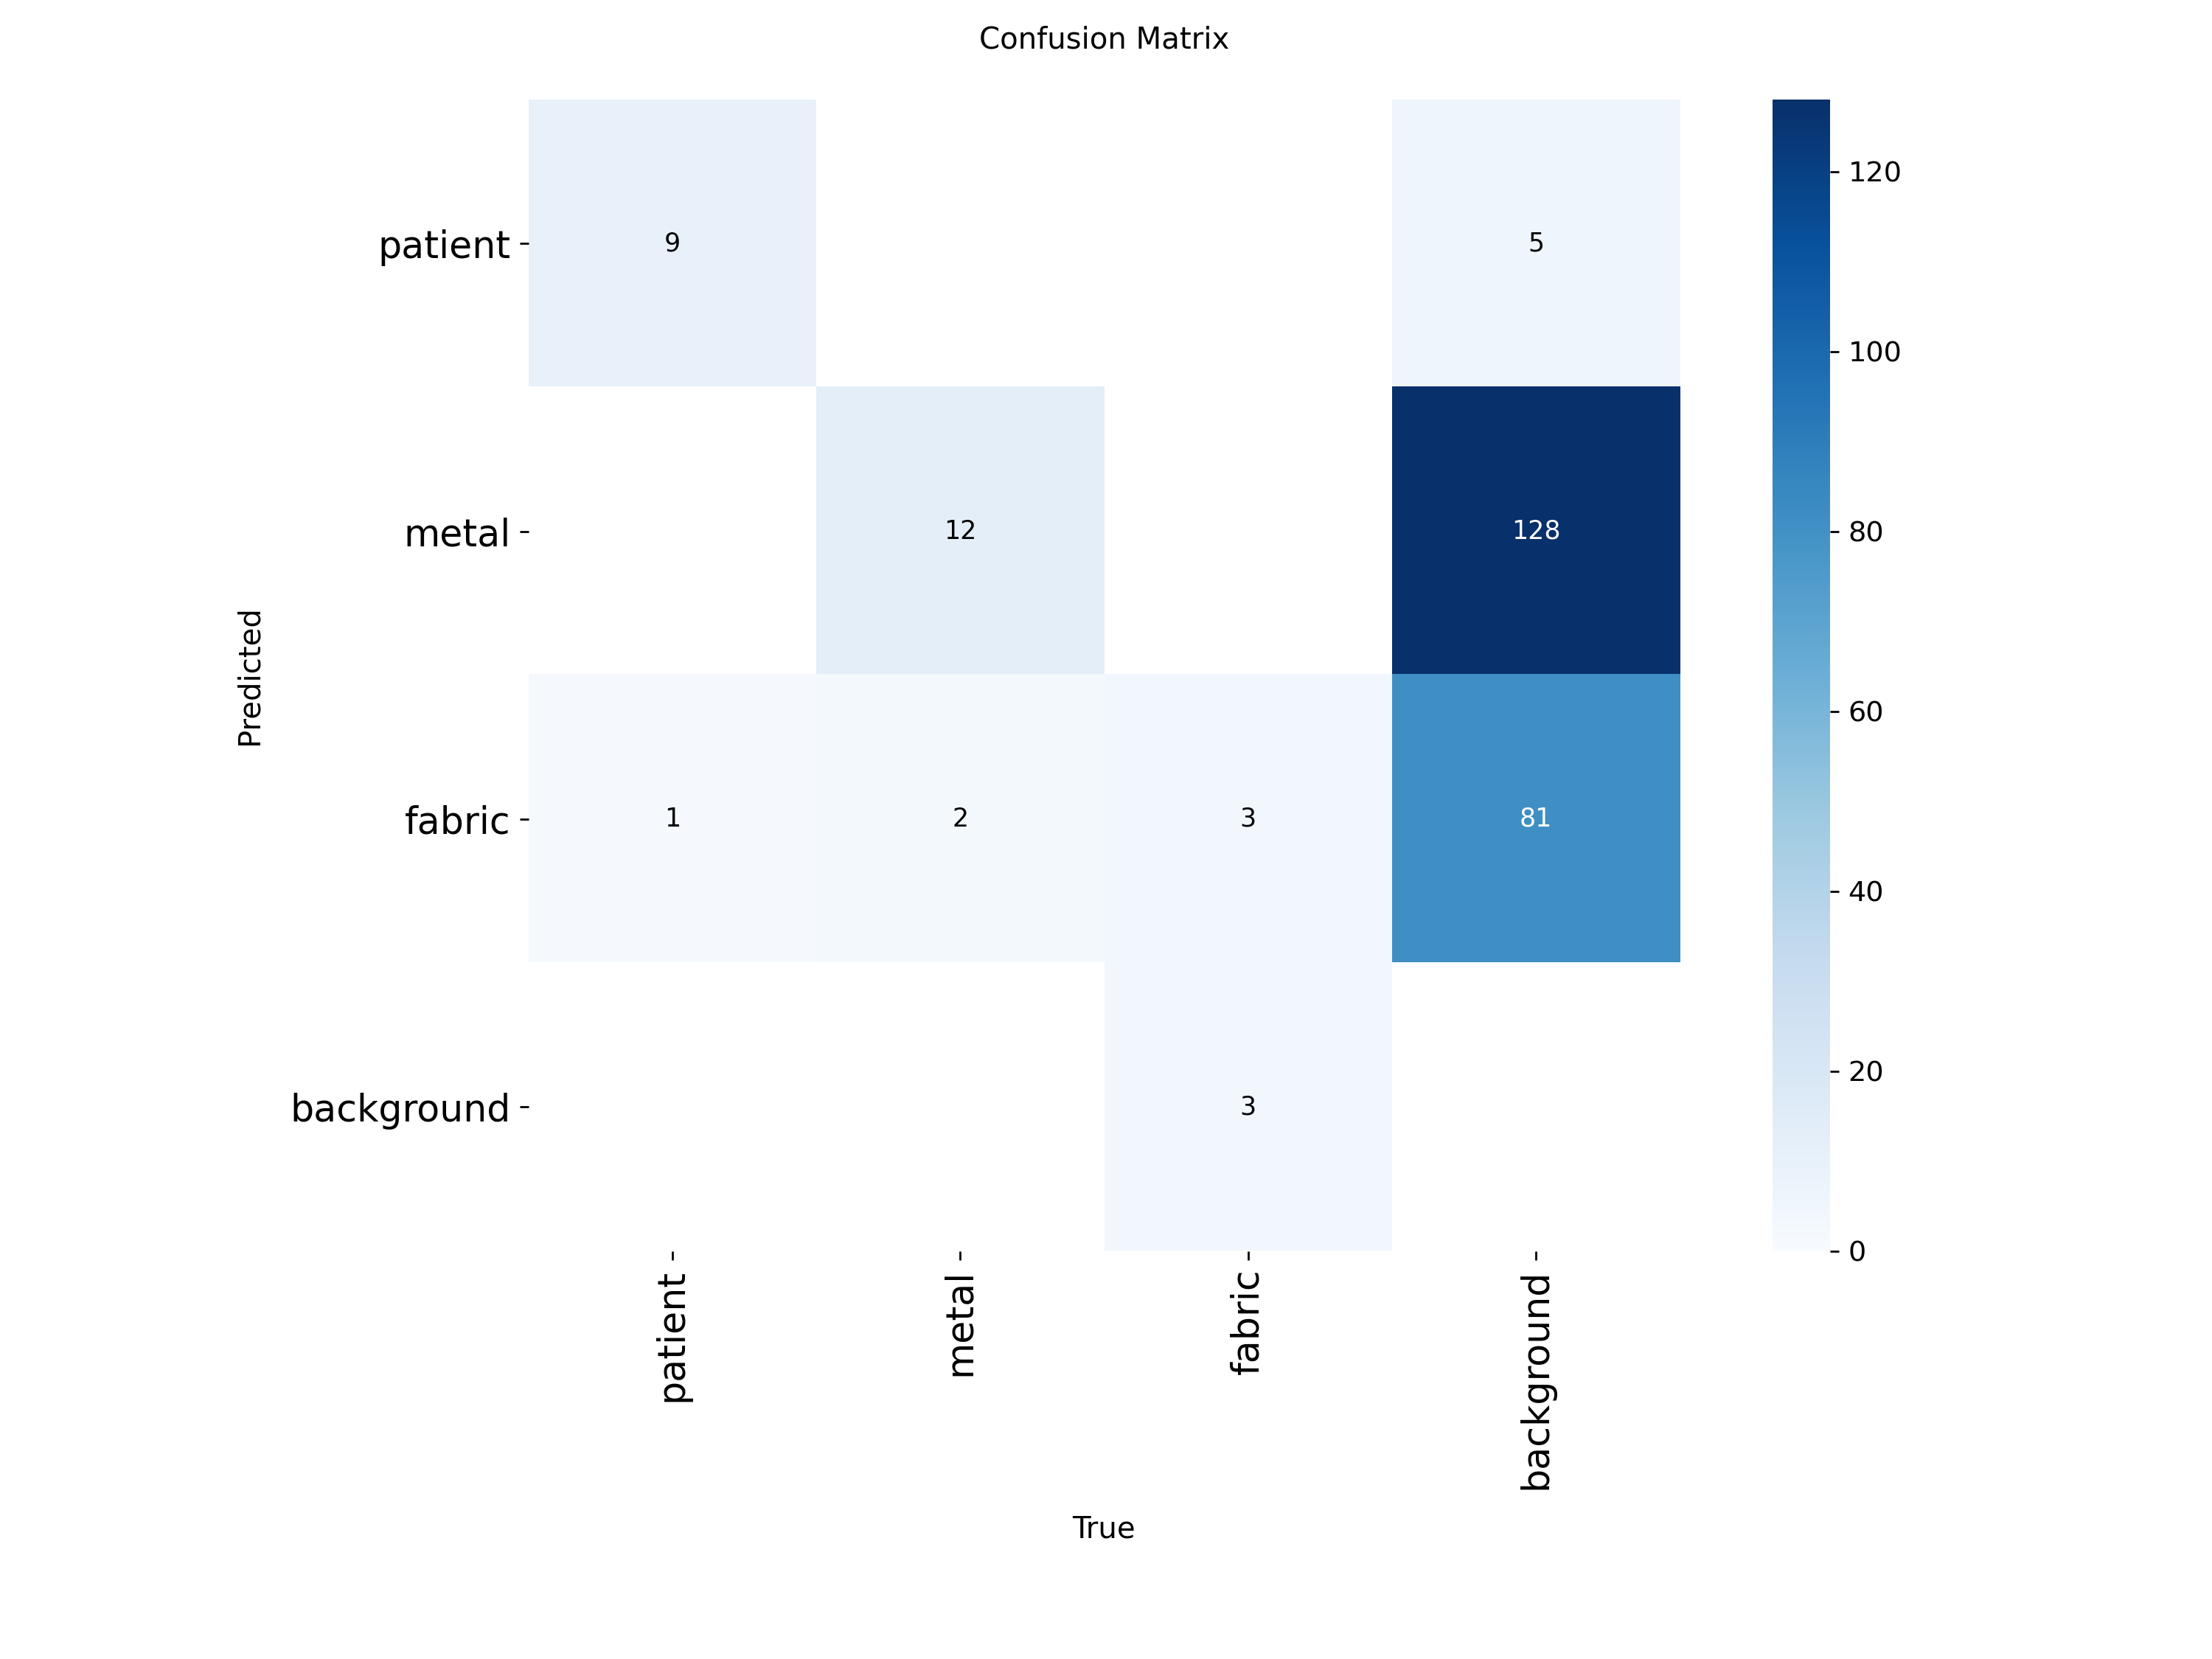

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train-2/confusion_matrix.png', width=600)

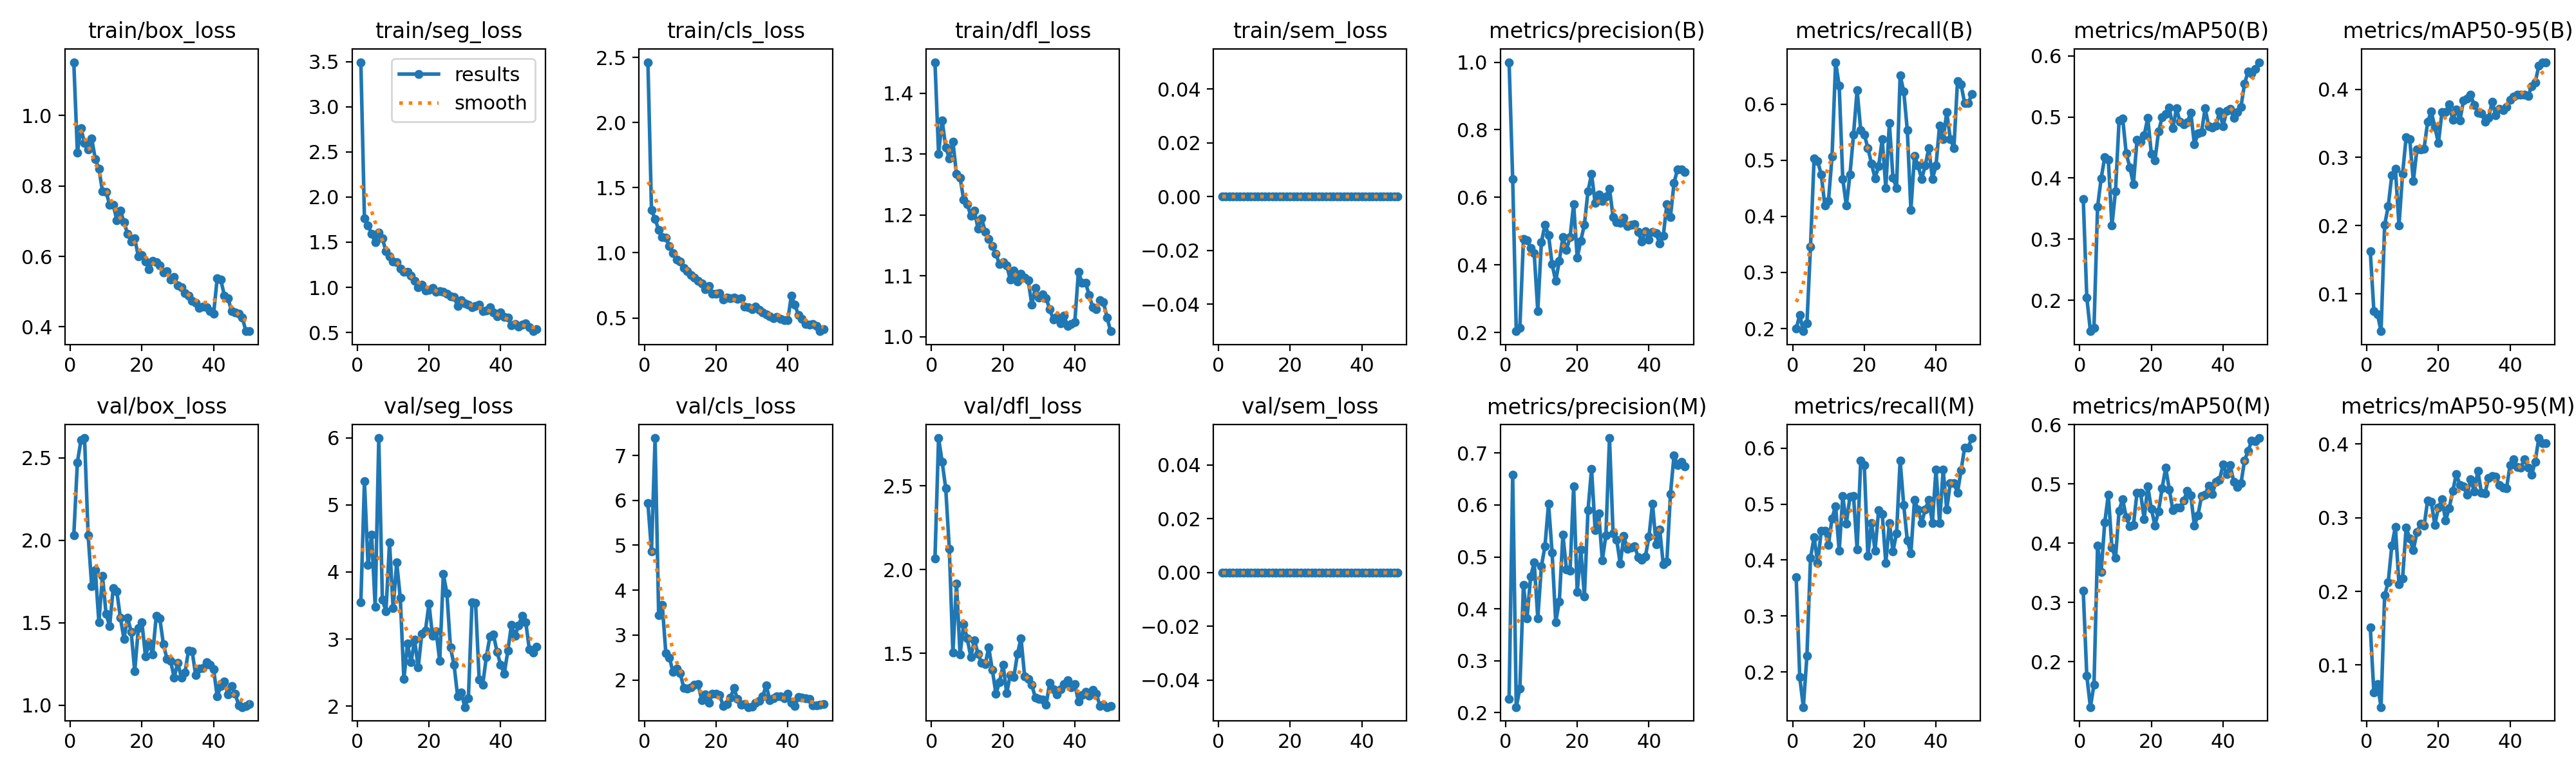

In [ ]:
display(Image(filename="/content/runs/segment/train-2/results.png", width=1200))

In [ ]:
model = YOLO("/content/runs/segment/train-2/weights/best.pt")
pred_results = model.predict(
    source="/content/YOLO_dataset_aug/images/val",
    conf=0.1,
    imgsz=640,
    device=0
)


image 1/9 /content/YOLO_dataset_aug/images/val/lowdose15_original.png: 640x640 1 patient, 1 metal, 1 fabric, 39.3ms
image 2/9 /content/YOLO_dataset_aug/images/val/低剂量16.png: 640x640 1 patient, 1 metal, 2 fabrics, 39.2ms
image 3/9 /content/YOLO_dataset_aug/images/val/侧位05.png: 640x640 1 patient, 1 fabric, 37.3ms
image 4/9 /content/YOLO_dataset_aug/images/val/发白01_original.png: 640x640 1 patient, 11 metals, 1 fabric, 36.6ms
image 5/9 /content/YOLO_dataset_aug/images/val/发白05.png: 640x640 1 patient, 11 metals, 1 fabric, 36.6ms
image 6/9 /content/YOLO_dataset_aug/images/val/对比度差12.png: 640x640 1 patient, 4 metals, 2 fabrics, 36.7ms
image 7/9 /content/YOLO_dataset_aug/images/val/整理16.png: 640x640 1 patient, 3 metals, 2 fabrics, 21.6ms
image 8/9 /content/YOLO_dataset_aug/images/val/金属面积大04.png: 640x640 1 patient, 5 metals, 21.5ms
image 9/9 /content/YOLO_dataset_aug/images/val/高剂量15.png: 640x640 1 patient, 6 metals, 21.0ms
Speed: 7.3ms preprocess, 32.2ms inference, 6.8ms postprocess per imag

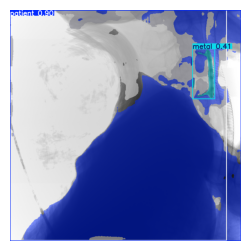

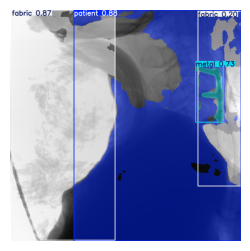

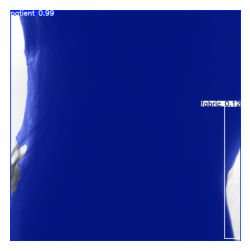

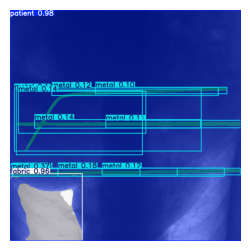

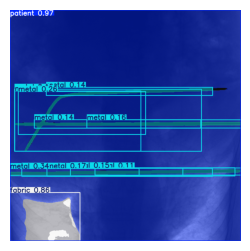

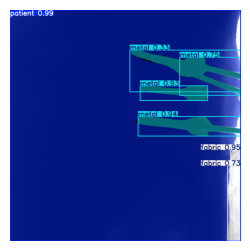

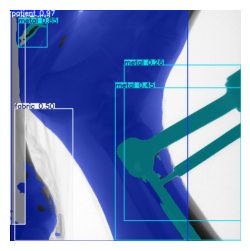

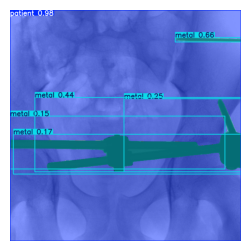

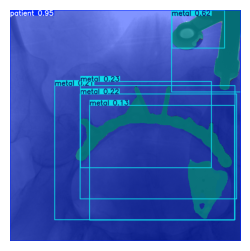

In [ ]:
import matplotlib.pyplot as plt

for result in pred_results:
    annotated = result.plot()

    plt.figure(figsize=(3, 3))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    #plt.title(result.path.split("/")[-1])
    plt.show()

In [ ]:
from google.colab import files
!zip -r /content/yolov8s_seg_50epochs_aug.zip /content/runs/segment/train-2
files.download("/content/yolov8s_seg_50epochs_aug.zip")

  adding: content/runs/segment/train-2/ (stored 0%)
  adding: content/runs/segment/train-2/args.yaml (deflated 52%)
  adding: content/runs/segment/train-2/train_batch1480.jpg (deflated 21%)
  adding: content/runs/segment/train-2/confusion_matrix.png (deflated 32%)
  adding: content/runs/segment/train-2/MaskPR_curve.png (deflated 21%)
  adding: content/runs/segment/train-2/labels.jpg (deflated 40%)
  adding: content/runs/segment/train-2/MaskF1_curve.png (deflated 12%)
  adding: content/runs/segment/train-2/results.png (deflated 7%)
  adding: content/runs/segment/train-2/train_batch1481.jpg (deflated 33%)
  adding: content/runs/segment/train-2/BoxR_curve.png (deflated 15%)
  adding: content/runs/segment/train-2/val_batch0_pred.jpg (deflated 21%)
  adding: content/runs/segment/train-2/BoxPR_curve.png (deflated 21%)
  adding: content/runs/segment/train-2/BoxP_curve.png (deflated 11%)
  adding: content/runs/segment/train-2/confusion_matrix_normalized.png (deflated 27%)
  adding: content/run

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

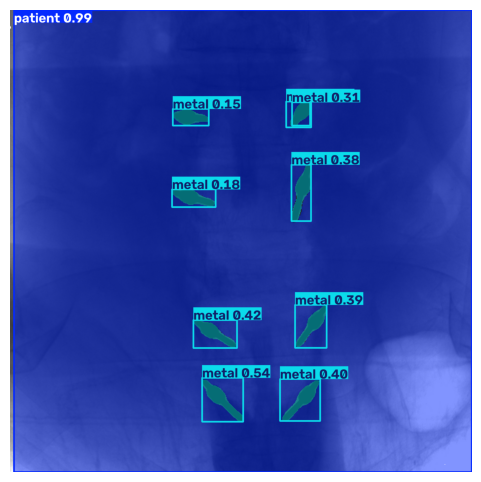

In [ ]:
for pic in results:
    annotated = pic.plot()

    plt.figure(figsize=(6, 6))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    #plt.title(pic.path.split("/")[-1])
    plt.show()

### 训练迭代：基于新增数据微调模型

从 Google Drive 加载上一轮训练保存的模型权重，并导入包含原有数据和新增标注数据的更新版数据集。在已有权重的基础上进行微调，完成后保存本轮模型权重和训练结果。

注意：数据集的类别编号及名称应与上一轮保持一致；新增数据应合理划分至训练集和验证集，避免同一图像及其增强版本跨集合出现。

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!cp "/content/drive/MyDrive/YOLO_dataset_new.zip" /content/
!unzip -q /content/YOLO_dataset_new.zip -d /content/
!ls -lh /content/YOLO_dataset_new.zip
!file /content/YOLO_dataset_new.zip

In [ ]:
%%writefile /content/YOLO_dataset_aug/data.yaml
path: /content/YOLO_dataset_aug

train: images/train
val: images/val

names:
  0: patient
  1: metal
  2: fabric

Overwriting /content/YOLO_dataset_aug/data.yaml


In [ ]:
# 基于上一轮的最佳模型权重，在更新后的数据集上微调。可根据选择进行数据增强。
!yolo task=segment mode=train model="/content/drive/MyDrive/best.pt" data=/content/YOLO_dataset_aug/data.yaml epochs=30 imgsz=640 batch=8 device=0

In [ ]:
from pathlib import Path
import shutil

# 改成本次训练实际输出的目录
run_dir = Path("/content/runs/segment/train-2")

# 每轮使用不同名称，方便区分
save_dir = Path("/content/drive/MyDrive/CT_segmentation/round_2")
save_dir.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(run_dir, save_dir)
print(f"训练结果已保存到：{save_dir}")


  adding: content/runs/segment/train-2/ (stored 0%)
  adding: content/runs/segment/train-2/args.yaml (deflated 52%)
  adding: content/runs/segment/train-2/train_batch1480.jpg (deflated 21%)
  adding: content/runs/segment/train-2/confusion_matrix.png (deflated 32%)
  adding: content/runs/segment/train-2/MaskPR_curve.png (deflated 21%)
  adding: content/runs/segment/train-2/labels.jpg (deflated 40%)
  adding: content/runs/segment/train-2/MaskF1_curve.png (deflated 12%)
  adding: content/runs/segment/train-2/results.png (deflated 7%)
  adding: content/runs/segment/train-2/train_batch1481.jpg (deflated 33%)
  adding: content/runs/segment/train-2/BoxR_curve.png (deflated 15%)
  adding: content/runs/segment/train-2/val_batch0_pred.jpg (deflated 21%)
  adding: content/runs/segment/train-2/BoxPR_curve.png (deflated 21%)
  adding: content/runs/segment/train-2/BoxP_curve.png (deflated 11%)
  adding: content/runs/segment/train-2/confusion_matrix_normalized.png (deflated 27%)
  adding: content/run

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🏆 Congratulations

### Learning Resources

Roboflow has produced many resources that you may find interesting as you advance your knowledge of computer vision:

- [Roboflow Notebooks](https://github.com/roboflow/notebooks): A repository of over 20 notebooks that walk through how to train custom models with a range of model types, from YOLOv7 to SegFormer.
- [Roboflow YouTube](https://www.youtube.com/c/Roboflow): Our library of videos featuring deep dives into the latest in computer vision, detailed tutorials that accompany our notebooks, and more.
- [Roboflow Discuss](https://discuss.roboflow.com/): Have a question about how to do something on Roboflow? Ask your question on our discussion forum.
- [Roboflow Models](https://roboflow.com): Learn about state-of-the-art models and their performance. Find links and tutorials to guide your learning.

### Convert data formats

Roboflow provides free utilities to convert data between dozens of popular computer vision formats. Check out [Roboflow Formats](https://roboflow.com/formats) to find tutorials on how to convert data between formats in a few clicks.

### Connect computer vision to your project logic

[Roboflow Templates](https://roboflow.com/templates) is a public gallery of code snippets that you can use to connect computer vision to your project logic. Code snippets range from sending emails after inference to measuring object distance between detections.